# 03b – Classification sur les données synthétiques : panne dans les 48 h ?

**Question :** à partir des mesures récentes d'une machine (capteurs + features glissantes), va-t-elle tomber en panne **dans les 48 prochaines heures** ?

**Entrée :** `data/processed/features_temporal.csv` (créé par `src/features.py`).
**Cible :** `failure_within_h` (1 = panne dans les 48 h, 0 sinon).
**Sorties :** `reports/tables/resultats_classification_synthetique.csv`, `reports/figures/classif_synth_*.png`, modèles dans `models/`.

**Différence avec `03_classification` (AI4I) :** ici les mesures forment des **historiques par machine**. Deux lignes d'une même machine se ressemblent énormément ; si on découpait au hasard, le modèle verrait la même machine en train et en test et ses scores seraient **gonflés**. On découpe donc **par machine** (`split_by_machine`), exactement comme dans `04_anomalies` et `07_etude_cout`.

Données **synthétiques** : les résultats montrent que la méthode fonctionne sur un cas simulé, pas sur une vraie usine.

## 1. Chargement et choix des variables

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.metrics import (average_precision_score, roc_auc_score, recall_score, precision_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay)
import xgboost
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "features.py").exists())
sys.path.insert(0, str(ROOT / "src"))
from features import split_by_machine, SENSOR_COLS
for d in ("reports/figures", "reports/tables", "models"):
    (ROOT / d).mkdir(parents=True, exist_ok=True)
SEED = 42

df = pd.read_csv(ROOT / "data/processed/features_temporal.csv")

# Variables d'entrée = capteurs + features glissantes (même choix que 04_anomalies).
# On exclut rul_h (durée de vie restante = la réponse !), age_h, time_h, load et les identifiants.
FEATURES = [c for c in df.columns if any(c.startswith(s) for s in SENSOR_COLS)]
print(len(FEATURES), "variables :", FEATURES[:6], "...")
print(df.shape)

# Garde-fou : aucune colonne interdite (réponse ou identifiant) dans le modèle
INTERDITES = {"rul_h", "failure_within_h", "age_h", "time_h", "cycle_id", "machine_id", "machine_type", "load"}
assert not INTERDITES & set(FEATURES), INTERDITES & set(FEATURES)
print("xgboost", xgboost.__version__)

30 variables : ['vib_rms', 'vib_kurtosis', 'vib_crest', 'temperature', 'pressure', 'current'] ...
(78836, 38)
xgboost 3.2.0


## 2. Découpage par machine

Les machines du jeu de **test** ne sont jamais vues à l'entraînement (même découpage que les notebooks 04 et 07, donc les résultats sont comparables).

In [2]:
train, test = split_by_machine(df, test_size=0.25, seed=SEED)
X_train, y_train, g_train = train[FEATURES], train["failure_within_h"], train["machine_id"]
X_test,  y_test = test[FEATURES], test["failure_within_h"]

print("machines train / test :", train.machine_id.nunique(), "/", test.machine_id.nunique())
print("lignes train / test   :", len(train), "/", len(test))
print("positifs train / test : {:.2%} / {:.2%}".format(y_train.mean(), y_test.mean()))
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print("une panne imminente pour {:.0f} mesures normales".format(ratio))

machines train / test : 45 / 15
lignes train / test   : 59155 / 19681
positifs train / test : 1.69% / 1.79%
une panne imminente pour 58 mesures normales


## 3. Évaluation : outils

Classes très déséquilibrées (~1,7 % de positifs) : l'**accuracy est trompeuse**. On regarde la **PR-AUC** (un modèle au hasard a une PR-AUC ≈ le taux de positifs), le **recall**, la **précision** et le **F1**.

La validation croisée est faite **par machine** (`GroupKFold`) pour la même raison que le découpage.

In [3]:
resultats = []
cv = GroupKFold(n_splits=5)

def cv_pr_auc(modele):
    s = cross_val_score(modele, X_train, y_train, groups=g_train, cv=cv,
                        scoring="average_precision", n_jobs=1)
    return s.mean(), s.std()

def evaluer(nom, modele, cv_stats, seuil=0.5):
    proba = modele.predict_proba(X_test)[:, 1]
    pred = (proba >= seuil).astype(int)
    resultats.append({
        "Modèle": nom,
        "PR-AUC (CV train)": cv_stats[0],
        "PR-AUC (test)": average_precision_score(y_test, proba),
        "ROC-AUC (test)": roc_auc_score(y_test, proba),
        "Recall": recall_score(y_test, pred),
        "Précision": precision_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred),
    })
    return proba, pred

## 4. Modèle 1 – régression logistique (référence)

Les variables sont normalisées (pipeline `StandardScaler` + régression), puis `class_weight="balanced"` donne plus de poids aux pannes.

In [4]:
logreg = make_pipeline(StandardScaler(),
                       LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED))
cvs = cv_pr_auc(logreg)
print("PR-AUC validation croisée par machine : {:.3f} ± {:.3f}".format(*cvs))
logreg.fit(X_train, y_train)
proba_lr, pred_lr = evaluer("Régression logistique", logreg, cvs)
pd.DataFrame(resultats).round(3)

PR-AUC validation croisée par machine : 0.868 ± 0.034


,Modèle,PR-AUC (CV train),PR-AUC (test),ROC-AUC (test),Recall,Précision,F1
0,Régression logistique,0.868,0.834,0.997,0.98,0.453,0.619


## 5. Modèle 2 – Random Forest

In [5]:
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=SEED)
cvs = cv_pr_auc(rf)
print("PR-AUC validation croisée par machine : {:.3f} ± {:.3f}".format(*cvs))
rf.fit(X_train, y_train)
proba_rf, pred_rf = evaluer("Random Forest", rf, cvs)
pd.DataFrame(resultats).round(3)

PR-AUC validation croisée par machine : 0.850 ± 0.045


,Modèle,PR-AUC (CV train),PR-AUC (test),ROC-AUC (test),Recall,Précision,F1
0,Régression logistique,0.868,0.834,0.997,0.98,0.453,0.619
1,Random Forest,0.850,0.883,0.998,0.92,0.695,0.792


## 6. Modèle 3 – XGBoost

`scale_pos_weight` = rapport normal / panne, pour compenser la rareté des pannes.

In [6]:
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                    colsample_bytree=0.8, scale_pos_weight=ratio, eval_metric="aucpr",
                    random_state=SEED, n_jobs=-1)
cvs = cv_pr_auc(xgb)
print("PR-AUC validation croisée par machine : {:.3f} ± {:.3f}".format(*cvs))
xgb.fit(X_train, y_train)
proba_xgb, pred_xgb = evaluer("XGBoost", xgb, cvs)
pd.DataFrame(resultats).round(3)

PR-AUC validation croisée par machine : 0.866 ± 0.034


,Modèle,PR-AUC (CV train),PR-AUC (test),ROC-AUC (test),Recall,Précision,F1
0,Régression logistique,0.868,0.834,0.997,0.980,0.453,0.619
1,Random Forest,0.850,0.883,0.998,0.920,0.695,0.792
2,XGBoost,0.866,0.892,0.998,0.966,0.633,0.765


## 7. Tableau final (à recopier dans le README)

In [7]:
tableau = pd.DataFrame(resultats).set_index("Modèle").round(3)
tableau.to_csv(ROOT / "reports/tables/resultats_classification_synthetique.csv")
print("Hasard : PR-AUC ≈ {:.3f}".format(y_test.mean()))
tableau

Hasard : PR-AUC ≈ 0.018


,PR-AUC (CV train),PR-AUC (test),ROC-AUC (test),Recall,Précision,F1
Modèle,,,,,,
Régression logistique,0.868,0.834,0.997,0.980,0.453,0.619
Random Forest,0.850,0.883,0.998,0.920,0.695,0.792
XGBoost,0.866,0.892,0.998,0.966,0.633,0.765


## 8. Courbes précision-rappel et matrices de confusion

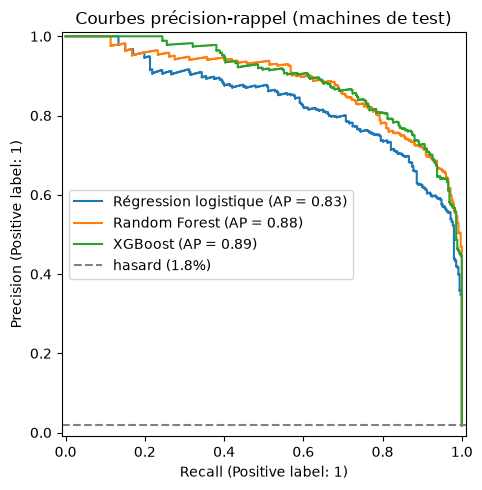

In [ ]:
modeles = [("Régression logistique", proba_lr, pred_lr), ("Random Forest", proba_rf, pred_rf), ("XGBoost", proba_xgb, pred_xgb)]

fig, ax = plt.subplots(figsize=(7, 5))
for nom, proba, _ in modeles:
    PrecisionRecallDisplay.from_predictions(y_test, proba, name=nom, ax=ax)
ax.axhline(y_test.mean(), color="gray", ls="--", label="hasard ({:.1%})".format(y_test.mean()))
ax.set_title("Courbes précision-rappel (machines de test)")
ax.legend()
plt.tight_layout()
plt.savefig(ROOT / "reports/figures/classif_synth_pr_curves.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nom, _, pred) in zip(axes, modeles):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Normal", "Panne <48 h"]).plot(
        ax=ax, colorbar=False, values_format="d")
    ax.set_title(nom)
plt.tight_layout()
plt.savefig(ROOT / "reports/figures/classif_synth_confusion.png", dpi=150)
plt.show()

## 9. Quelles variables comptent le plus ? (Random Forest)

In [ ]:
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values().tail(15)
imp.plot(kind="barh", figsize=(7, 5), color="steelblue")
plt.title("15 variables les plus importantes (Random Forest)")
plt.tight_layout()
plt.savefig(ROOT / "reports/figures/classif_synth_importance_rf.png", dpi=150)
plt.show()

## 10. Sauvegarde des modèles

Ils seront réutilisés par l'étape SHAP et par le choix du seuil selon le coût.

In [ ]:
joblib.dump(logreg, ROOT / "models/classif_synth_logreg.pkl")
joblib.dump(rf, ROOT / "models/classif_synth_random_forest.pkl")
joblib.dump(xgb, ROOT / "models/classif_synth_xgboost.pkl")
print("Modèles sauvegardés dans models/")

## À retenir

- **Seuil 0,5 = choix par défaut.** Rater une panne coûte bien plus cher qu'une fausse alerte : l'étape suivante choisira le seuil qui **minimise le coût** (hypothèses de `07_etude_cout`).
- Les features glissantes sont calculées **machine par machine et cycle par cycle**, avec le passé seulement : pas de fuite du futur.
- Si le résultat est très bon, c'est en partie parce que la dégradation est **simulée** (`hp = (âge/durée de vie)³`) : le signal est plus propre qu'en vrai.
- Prochaines étapes : **SHAP** (pourquoi une alerte ?) puis **seuil de coût**.